# SMS Spam Detection: Model Training

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, roc_auc_score,
)

## Data

In [2]:
DATA_PATH = next(p for p in [Path("../data/sms.tsv"), Path("data/sms.tsv"), Path("sms.tsv")] if p.exists())
MODEL_DIR = next((p for p in [Path("../app"), Path("app")] if p.exists()), Path("."))

df = pd.read_csv(DATA_PATH, sep="\t", header=None, names=["label", "message"])

# exact duplicates can land in both train and test and inflate the score
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
df["target"] = (df["label"] == "spam").astype(int)

print(f"Dropped {before - len(df)} duplicates -> {len(df)} messages, spam rate {df['target'].mean():.1%}")

Dropped 403 duplicates -> 5169 messages, spam rate 12.6%


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["message"], df["target"], test_size=0.2, random_state=42, stratify=df["target"]
)

print(len(X_train), len(X_test))
print(f"Majority-class baseline accuracy: {1 - y_test.mean():.3f}")

4135 1034
Majority-class baseline accuracy: 0.873


## Step 1: compare classifiers on word TF-IDF

In [4]:
def make_pipeline(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf", clf),
    ])

models = {
    "Naive Bayes": make_pipeline(MultinomialNB()),
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Linear SVM": make_pipeline(LinearSVC(class_weight="balanced")),
    "Random Forest": make_pipeline(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
}

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ["precision", "recall", "f1"]


def cv_table(candidates):
    rows = []
    for name, pipe in candidates.items():
        scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metrics)
        rows.append({
            "model": name,
            **{m: scores[f"test_{m}"].mean() for m in metrics},
            "f1_std": scores["test_f1"].std(),
        })
    return pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False).round(4)


cv_results = cv_table(models)
cv_results

,precision,recall,f1,f1_std
model,,,,
Linear SVM,0.9537,0.8966,0.9240,0.0178
Logistic Regression,0.9197,0.9138,0.9166,0.0169
Random Forest,0.9906,0.8085,0.8900,0.0214
Naive Bayes,1.0000,0.7529,0.8588,0.0167


## Step 2: feature engineering (Logistic Regression, same CV folds)

In [6]:
def numeric_features(texts):
    s = pd.Series(list(texts))
    return np.c_[s.str.len(), s.str.count(r"\d"), s.apply(lambda t: sum(c.isupper() for c in t) / max(len(t), 1))]


def word_tfidf():
    return TfidfVectorizer(stop_words="english", min_df=2, sublinear_tf=True)


def char_tfidf():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)


def numeric_block():
    return Pipeline([("extract", FunctionTransformer(numeric_features)), ("scale", MaxAbsScaler())])


def lr_pipeline(*blocks):
    return Pipeline([
        ("features", FeatureUnion(list(blocks))),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=5)),
    ])


variants = {
    "word TF-IDF": lr_pipeline(("word", word_tfidf())),
    "+ numeric features": lr_pipeline(("word", word_tfidf()), ("num", numeric_block())),
    "+ character n-grams": lr_pipeline(("word", word_tfidf()), ("char", char_tfidf())),
    "+ both": lr_pipeline(("word", word_tfidf()), ("char", char_tfidf()), ("num", numeric_block())),
}

In [7]:
ablation = cv_table(variants)
ablation

,precision,recall,f1,f1_std
model,,,,
+ character n-grams,0.9863,0.9406,0.9628,0.0062
+ both,0.9823,0.9386,0.9598,0.0052
+ numeric features,0.9534,0.9348,0.9439,0.0063
word TF-IDF,0.9453,0.9158,0.9302,0.0157


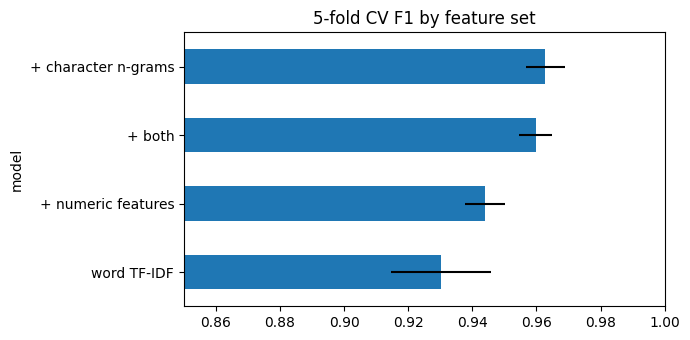

In [8]:
ablation["f1"].plot(kind="barh", xerr=ablation["f1_std"], figsize=(7, 3.5), title="5-fold CV F1 by feature set")
plt.xlim(0.85, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Step 3: tune the chosen setup (word + character n-grams)

In [9]:
param_grid = {
    "features__word__min_df": [1, 2],
    "features__char__ngram_range": [(2, 4), (2, 5)],
    "clf__C": [1, 5, 10, 20],
}

search = GridSearchCV(variants["+ character n-grams"], param_grid, scoring="f1", cv=cv, n_jobs=-1)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV F1:", round(search.best_score_, 4))
best_model = search.best_estimator_

Best params: {'clf__C': 5, 'features__char__ngram_range': (2, 4), 'features__word__min_df': 2}
Best CV F1: 0.9677


## Final evaluation on the held-out test set

In [10]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=4))
print("ROC AUC:", round(roc_auc_score(y_test, y_proba), 4))

              precision    recall  f1-score   support

         ham     0.9923    0.9934    0.9928       903
        spam     0.9538    0.9466    0.9502       131

    accuracy                         0.9874      1034
   macro avg     0.9731    0.9700    0.9715      1034
weighted avg     0.9874    0.9874    0.9874      1034

ROC AUC: 0.9981


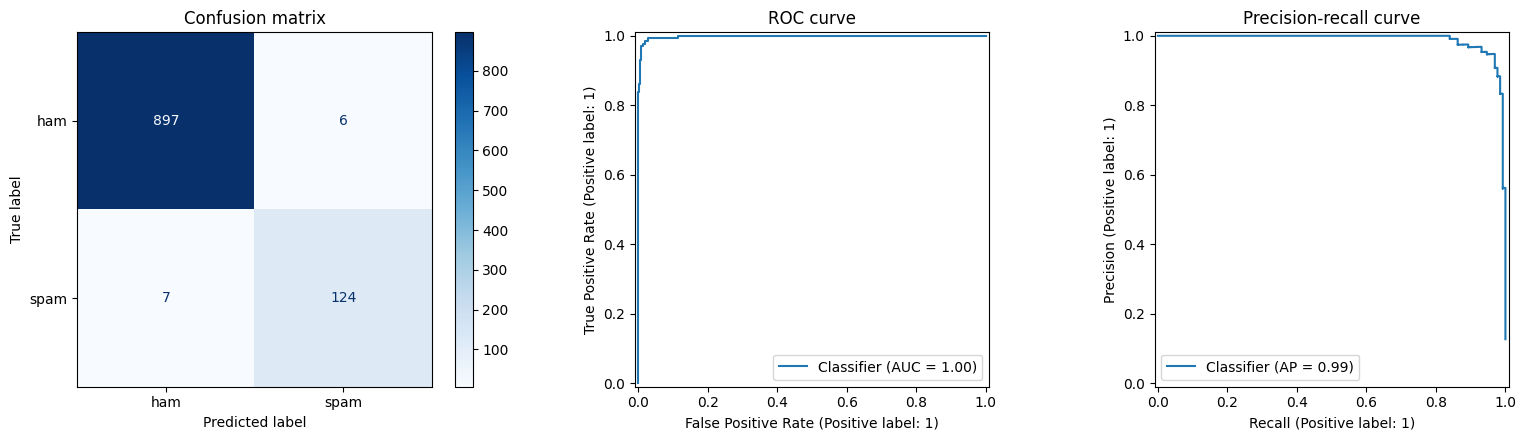

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["ham", "spam"], cmap="Blues", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2])
axes[0].set_title("Confusion matrix")
axes[1].set_title("ROC curve")
axes[2].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

## Save model

In [12]:
# drop the large set of ignored n-grams to keep the file small
for _, vectorizer in best_model.named_steps["features"].transformer_list:
    vectorizer.stop_words_ = None

joblib.dump(best_model, MODEL_DIR / "spam_model.pkl")
print("Saved:", MODEL_DIR / "spam_model.pkl", f"({(MODEL_DIR / 'spam_model.pkl').stat().st_size / 1e6:.1f} MB)")

Saved: ../app/spam_model.pkl (0.6 MB)
